SMZ26-F27: 87 raw bars; warmup sufficient=True
SMF27-H27: 87 raw bars; warmup sufficient=True
SMH27-K27: 87 raw bars; warmup sufficient=True
SMK27-N27: 87 raw bars; warmup sufficient=True
SMN27-Q27: 87 raw bars; warmup sufficient=True
SMZ26-H27: 87 raw bars; warmup sufficient=True
SMZ26-K27: 87 raw bars; warmup sufficient=True
SMF27-K27: 87 raw bars; warmup sufficient=True
SMF27-N27: 87 raw bars; warmup sufficient=False
SMH27-N27: 87 raw bars; warmup sufficient=False
Analysis: 2026-06-01 to 2026-10-04


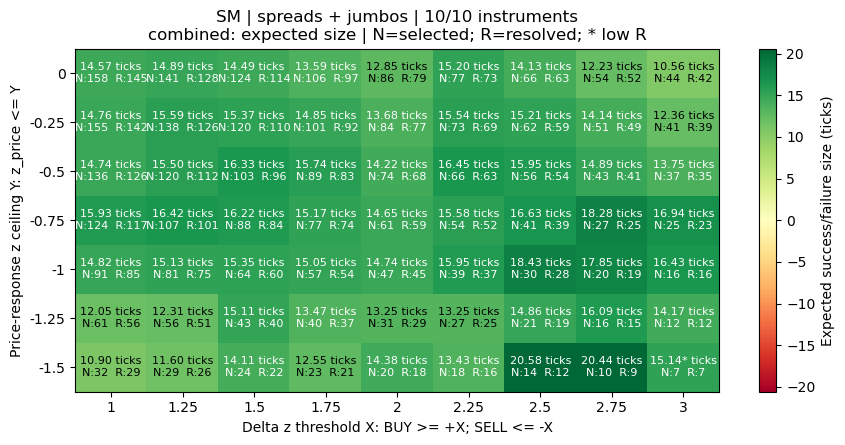

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed,n_instruments
0,combined,1.0,0.00,14.565271,158,145,113,32,22.637168,13.938616,1,12,505,10
1,combined,1.0,-0.25,14.761066,155,142,112,30,22.348214,13.564286,1,12,408,10
2,combined,1.0,-0.50,14.738379,136,126,98,28,22.816327,13.534439,1,9,314,10
3,combined,1.0,-0.75,15.926129,124,117,94,23,22.989362,12.940994,0,7,174,10
4,combined,1.0,-1.00,14.816387,91,85,66,19,22.651515,12.400376,1,5,79,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,combined,3.0,-0.50,13.748980,37,35,28,7,19.642857,9.826531,0,2,34,10
59,combined,3.0,-0.75,16.944099,25,23,20,3,20.900000,9.428571,0,2,19,10
60,combined,3.0,-1.00,16.428571,16,16,15,1,18.266667,11.142857,0,0,9,10
61,combined,3.0,-1.25,14.166667,12,12,12,0,14.166667,NaN,0,0,1,10


In [1]:
import sys
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = Path(
    r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis"
)
if str(PROJECT_DIR.parent) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR.parent))

# Reload so an existing notebook kernel uses the updated code/config.
config = importlib.import_module("market_analysis.config")
importlib.reload(config)

analysis = importlib.import_module(
    "market_analysis.finding_threshold.expected_profit_analysis"
)
importlib.reload(analysis)

# ---------- Customize these ----------
PRODUCT_CODE = "SM"             # "SM" or "BO"
FRONT_N = 5                    # five spreads + five jumbos
CANDLE_LENGTHS = [1, 2, 3, 5]
MODE = "combined"              # For only 1D: "separate" and [1]
PLOT_BY_STRUCTURE = False       # True adds spread/jumbo heatmaps

# X: one positive magnitude threshold, applied to both signed tails.
DELTA_Z_GRID = np.round(np.arange(1.0, 3.25, 0.25), 6)

# Y: ceiling on z-score of absolute price response.
# np.arange excludes the stop. Change start/stop/step freely.
PRICE_Z_GRID = np.round(np.arange(0.0, -1.75, -0.25), 6)

PARAMS = dict(config.ABSORPTION_EXPECTED_PROFIT)
PARAMS.update({
    "months_back": 5,             # October -> analysis starts 1 June
    "baseline_window": 15,
    "baseline_min_periods": 15,   # <= baseline_window
    "volume_window": 5,
    "atr_window": 5,
    "atr_period": 14,
    "stop_atr_mult": 1.5,
    "required_move_ticks": 2,     # Profit required BEFORE stop
    "forward_days": 10,          # Future raw 1D trading bars
})

# ---------- Fetch and analyze ----------
run = analysis.run_expected_profit_analysis(
    product_code=PRODUCT_CODE,
    candle_lengths=CANDLE_LENGTHS,
    mode=MODE,
    params=PARAMS,
    delta_z_grid=DELTA_Z_GRID,
    price_z_grid=PRICE_Z_GRID,
    front_n=FRONT_N,
    save_outputs=False,
)

print(
    f"Analysis: {run['analysis_start'].date()} "
    f"to {run['analysis_end'].date()}"
)
if run["errors"]:
    display(pd.DataFrame(
        list(run["errors"].items()),
        columns=["Instrument", "Error"],
    ))

# Pool actual events across all spreads/jumbos, not instrument averages.
pooled = analysis.pool_expected_profit_analysis(run)
groups = list(dict.fromkeys(
    pooled["threshold_table"]["analysis_group"]
))

# Combined mode produces one pooled heatmap.
# Separate mode produces one heatmap per requested candle length.
for group in groups:
    analysis.plot_expected_profit_heatmap(
        pooled, analysis_group=group
    )
    plt.show()

# Optional structure heatmaps reuse the same fetched data.
if PLOT_BY_STRUCTURE:
    for structure in run["universe"]:
        if any(
            r["metadata"]["structure"] == structure
            for r in run["instruments"].values()
        ):
            structure_pool = analysis.pool_expected_profit_analysis(
                run, structure=structure
            )
            for group in groups:
                analysis.plot_expected_profit_heatmap(
                    structure_pool, analysis_group=group
                )
                plt.show()

# Detailed values behind each heatmap cell.
display(pooled["threshold_table"][[
    "analysis_group",
    "delta_z_threshold",
    "price_z_threshold",
    "expected_profit_ticks",
    "n_signals",
    "n_resolved",
    "n_success",
    "n_failure",
    "avg_success_ticks",
    "avg_failure_ticks",
    "n_unresolved",
    "n_censored",
    "n_suppressed",
    "n_instruments",
]])

SMZ26-F27: 90 raw bars; warmup sufficient=True
SMF27-H27: 90 raw bars; warmup sufficient=True
SMH27-K27: 90 raw bars; warmup sufficient=True
SMK27-N27: 90 raw bars; warmup sufficient=True
SMN27-Q27: 90 raw bars; warmup sufficient=True
SMZ26-H27: 90 raw bars; warmup sufficient=True
SMZ26-K27: 90 raw bars; warmup sufficient=True
SMF27-K27: 90 raw bars; warmup sufficient=True
SMF27-N27: 90 raw bars; warmup sufficient=False
SMH27-N27: 90 raw bars; warmup sufficient=False
Analysis: 2026-06-01 to 2026-10-07

SPREAD
SMZ26-F27


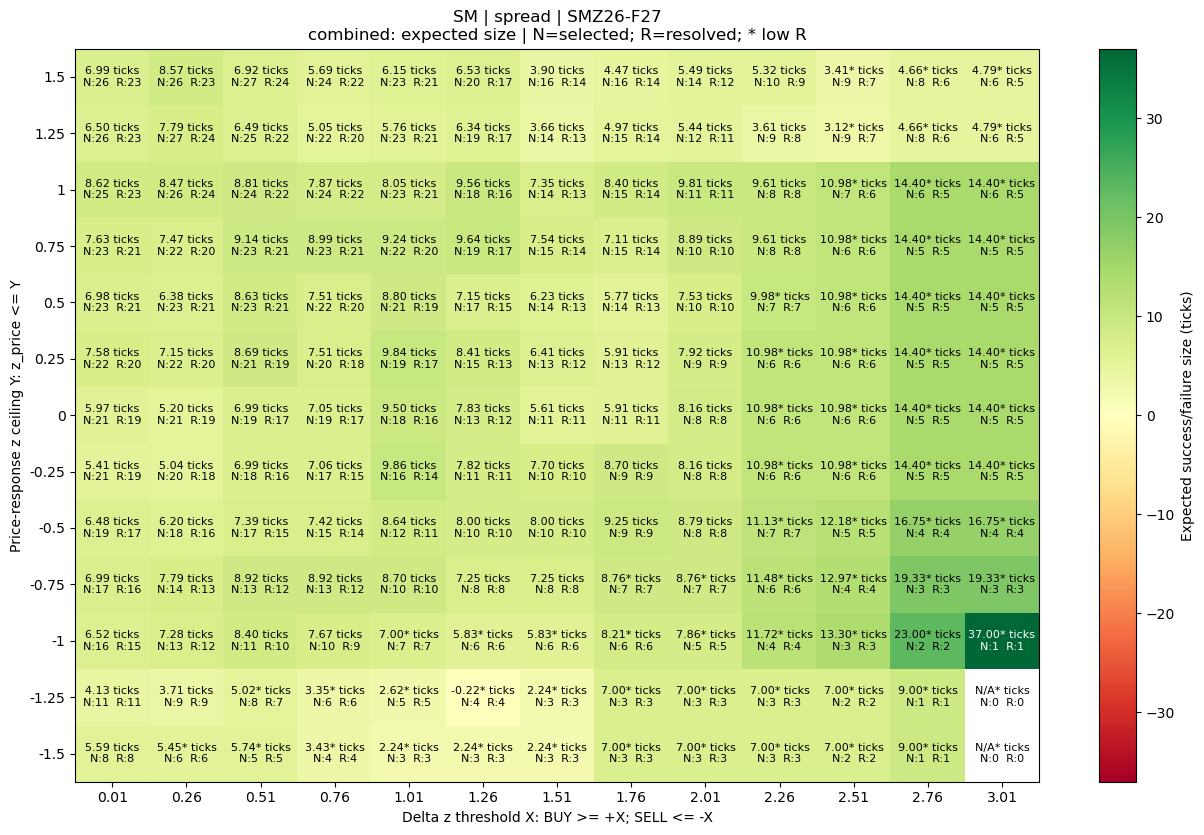

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,0.01,1.50,6.990683,26,23,18,5,10.777778,6.642857,0,3,215
1,combined,0.01,1.25,6.503106,26,23,18,5,10.166667,6.685714,0,3,203
2,combined,0.01,1.00,8.619565,25,23,19,4,12.368421,9.187500,0,2,187
3,combined,0.01,0.75,7.630952,23,21,17,4,11.588235,9.187500,0,2,167
4,combined,0.01,0.50,6.982993,23,21,16,5,11.937500,8.871429,0,2,153
...,...,...,...,...,...,...,...,...,...,...,...,...,...
164,combined,3.01,-0.50,16.750000,4,4,4,0,16.750000,NaN,0,0,1
165,combined,3.01,-0.75,19.333333,3,3,3,0,19.333333,NaN,0,0,0
166,combined,3.01,-1.00,37.000000,1,1,1,0,37.000000,NaN,0,0,0
167,combined,3.01,-1.25,NaN,0,0,0,0,NaN,NaN,0,0,0


SMF27-H27


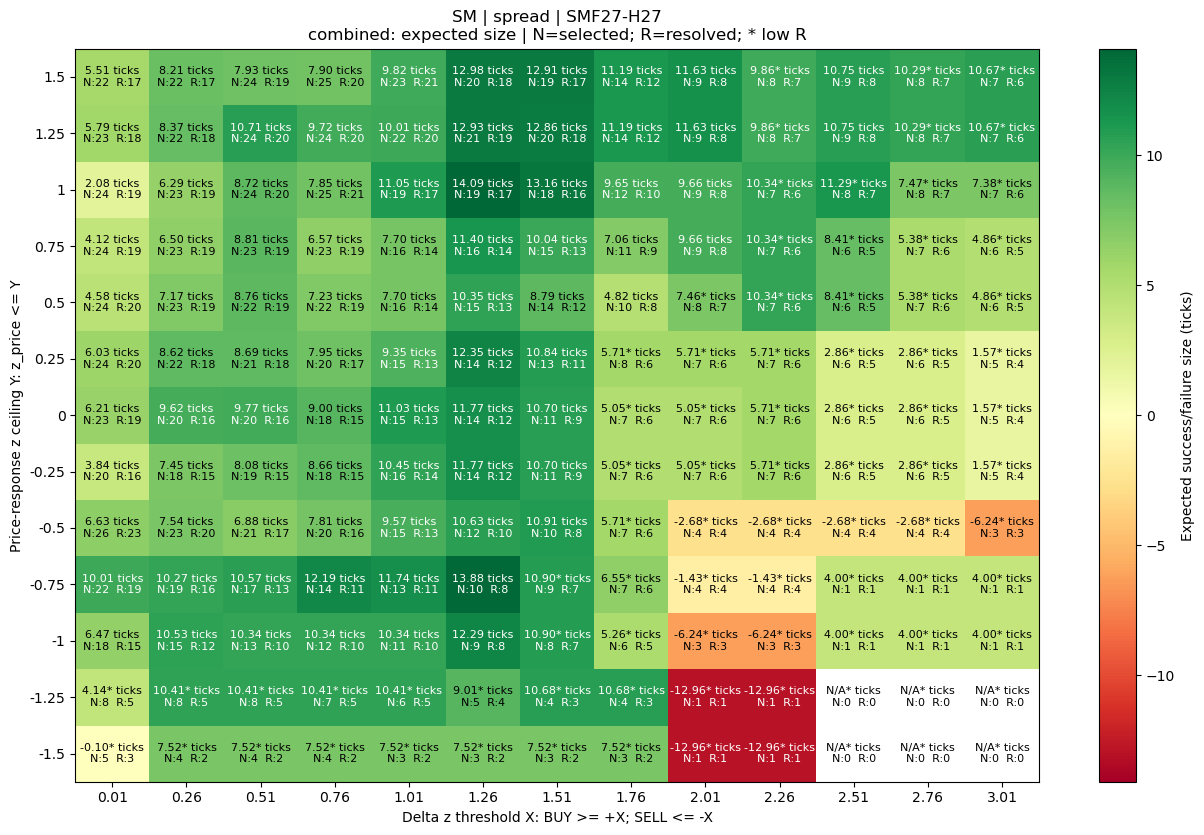

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,0.01,1.50,5.506303,22,17,11,6,14.909091,11.732143,1,4,224
1,combined,0.01,1.25,5.793651,23,18,11,7,17.272727,12.244898,1,4,208
2,combined,0.01,1.00,2.084586,24,19,10,9,14.900000,12.154762,1,4,190
3,combined,0.01,0.75,4.116541,24,19,11,8,15.545455,11.598214,1,4,176
4,combined,0.01,0.50,4.580357,24,20,13,7,13.384615,11.770408,1,3,165
...,...,...,...,...,...,...,...,...,...,...,...,...,...
164,combined,3.01,-0.50,-6.238095,3,3,1,2,4.000000,11.357143,0,0,0
165,combined,3.01,-0.75,4.000000,1,1,1,0,4.000000,NaN,0,0,0
166,combined,3.01,-1.00,4.000000,1,1,1,0,4.000000,NaN,0,0,0
167,combined,3.01,-1.25,NaN,0,0,0,0,NaN,NaN,0,0,0


SMH27-K27


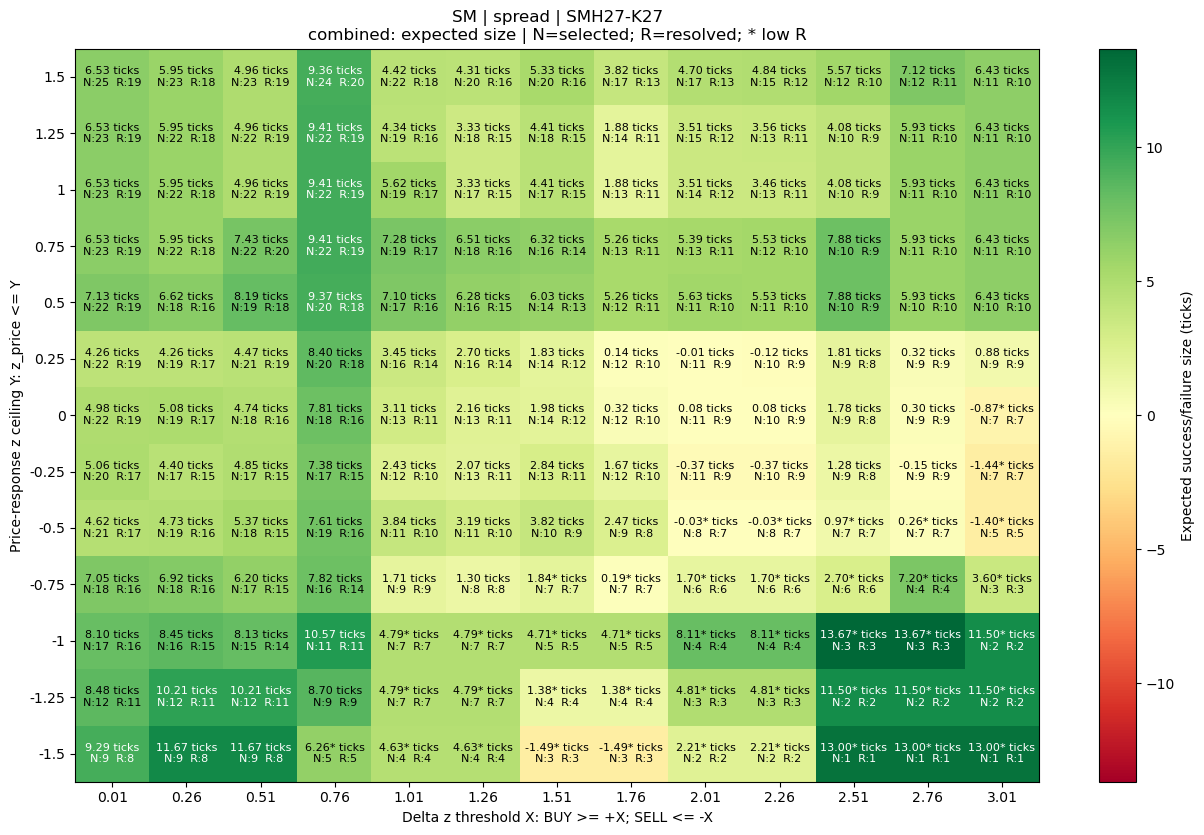

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,0.01,1.50,6.531955,25,19,14,5,12.285714,9.578571,0,6,218
1,combined,0.01,1.25,6.531955,23,19,14,5,12.285714,9.578571,0,4,205
2,combined,0.01,1.00,6.531955,23,19,14,5,12.285714,9.578571,0,4,192
3,combined,0.01,0.75,6.531955,23,19,14,5,12.285714,9.578571,0,4,176
4,combined,0.01,0.50,7.127820,22,19,14,5,13.071429,9.514286,0,3,155
...,...,...,...,...,...,...,...,...,...,...,...,...,...
164,combined,3.01,-0.50,-1.400000,5,5,2,3,11.500000,10.000000,0,0,4
165,combined,3.01,-0.75,3.595238,3,3,2,1,11.500000,12.214286,0,0,1
166,combined,3.01,-1.00,11.500000,2,2,2,0,11.500000,NaN,0,0,1
167,combined,3.01,-1.25,11.500000,2,2,2,0,11.500000,NaN,0,0,0


SMK27-N27


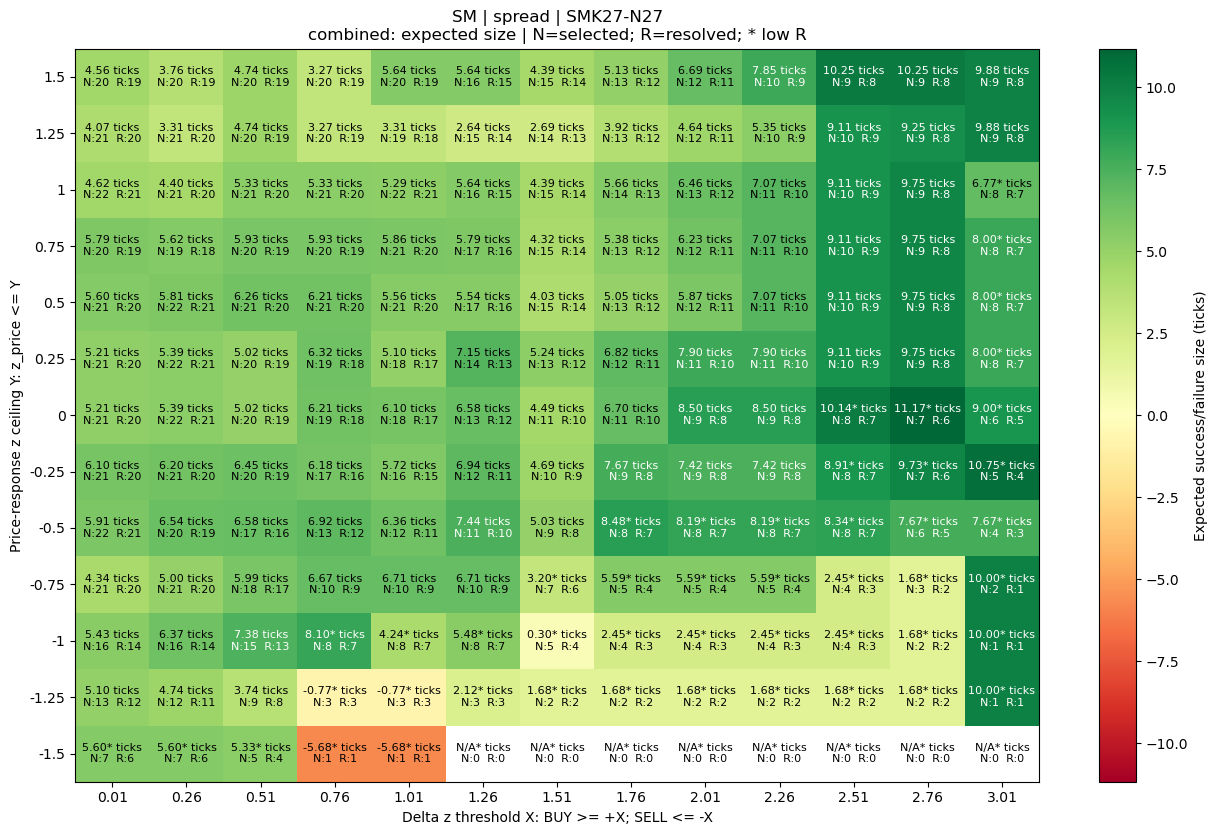

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,0.01,1.50,4.556391,20,19,14,5,8.785714,7.285714,0,1,234
1,combined,0.01,1.25,4.066071,21,20,14,6,9.214286,7.946429,0,1,226
2,combined,0.01,1.00,4.615646,22,21,15,6,9.333333,7.178571,0,1,208
3,combined,0.01,0.75,5.793233,20,19,15,4,9.466667,7.982143,0,1,198
4,combined,0.01,0.50,5.600000,21,20,16,4,8.875000,7.500000,0,1,181
...,...,...,...,...,...,...,...,...,...,...,...,...,...
164,combined,3.01,-0.50,7.666667,4,3,3,0,7.666667,NaN,0,1,0
165,combined,3.01,-0.75,10.000000,2,1,1,0,10.000000,NaN,0,1,0
166,combined,3.01,-1.00,10.000000,1,1,1,0,10.000000,NaN,0,0,0
167,combined,3.01,-1.25,10.000000,1,1,1,0,10.000000,NaN,0,0,0


SMN27-Q27


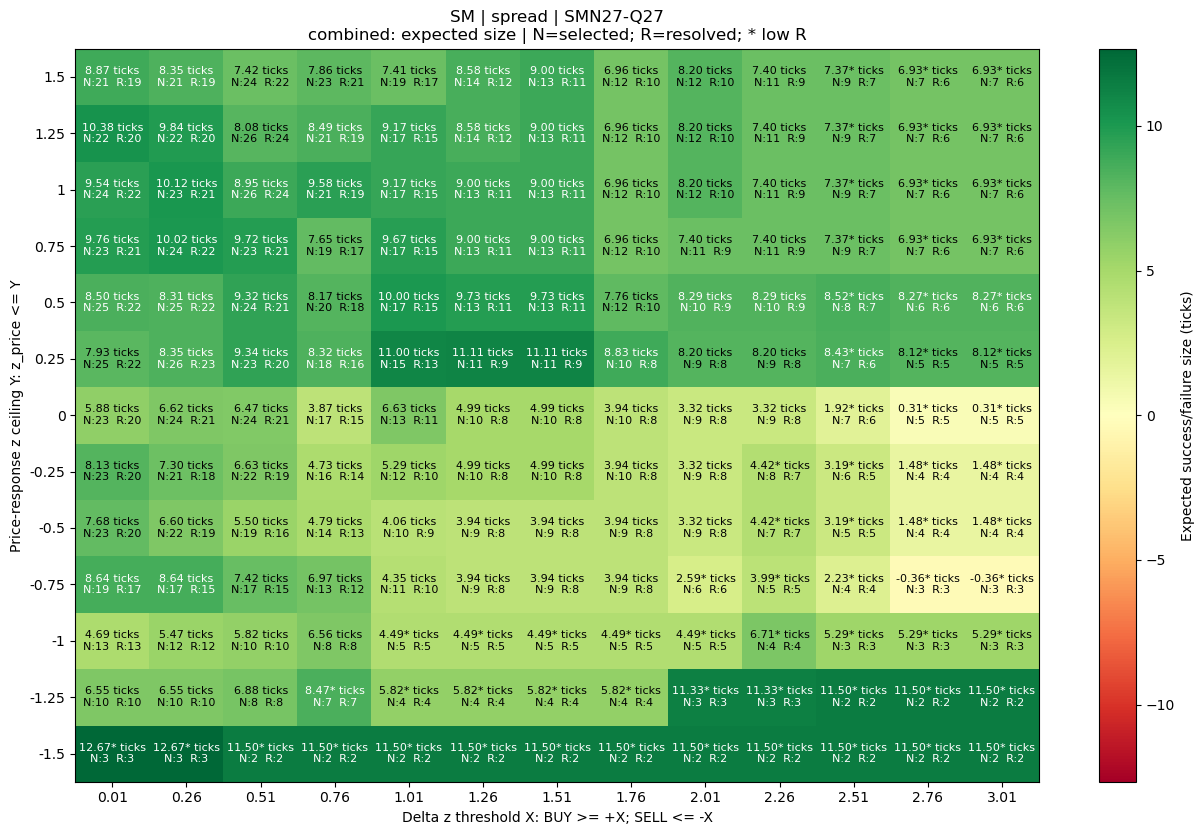

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,0.01,1.50,8.866541,21,19,16,3,11.500000,5.178571,0,2,212
1,combined,0.01,1.25,10.383929,22,20,18,2,12.055556,4.660714,0,2,201
2,combined,0.01,1.00,9.540584,24,22,19,3,11.842105,5.035714,0,2,185
3,combined,0.01,0.75,9.756803,23,21,18,3,12.222222,5.035714,0,2,172
4,combined,0.01,0.50,8.495130,25,22,17,5,12.411765,4.821429,0,3,158
...,...,...,...,...,...,...,...,...,...,...,...,...,...
164,combined,3.01,-0.50,1.482143,4,4,2,2,11.000000,8.035714,0,0,10
165,combined,3.01,-0.75,-0.357143,3,3,1,2,15.000000,8.035714,0,0,7
166,combined,3.01,-1.00,5.285714,3,3,2,1,13.500000,11.142857,0,0,3
167,combined,3.01,-1.25,11.500000,2,2,2,0,11.500000,NaN,0,0,1



JUMBO
SMZ26-H27


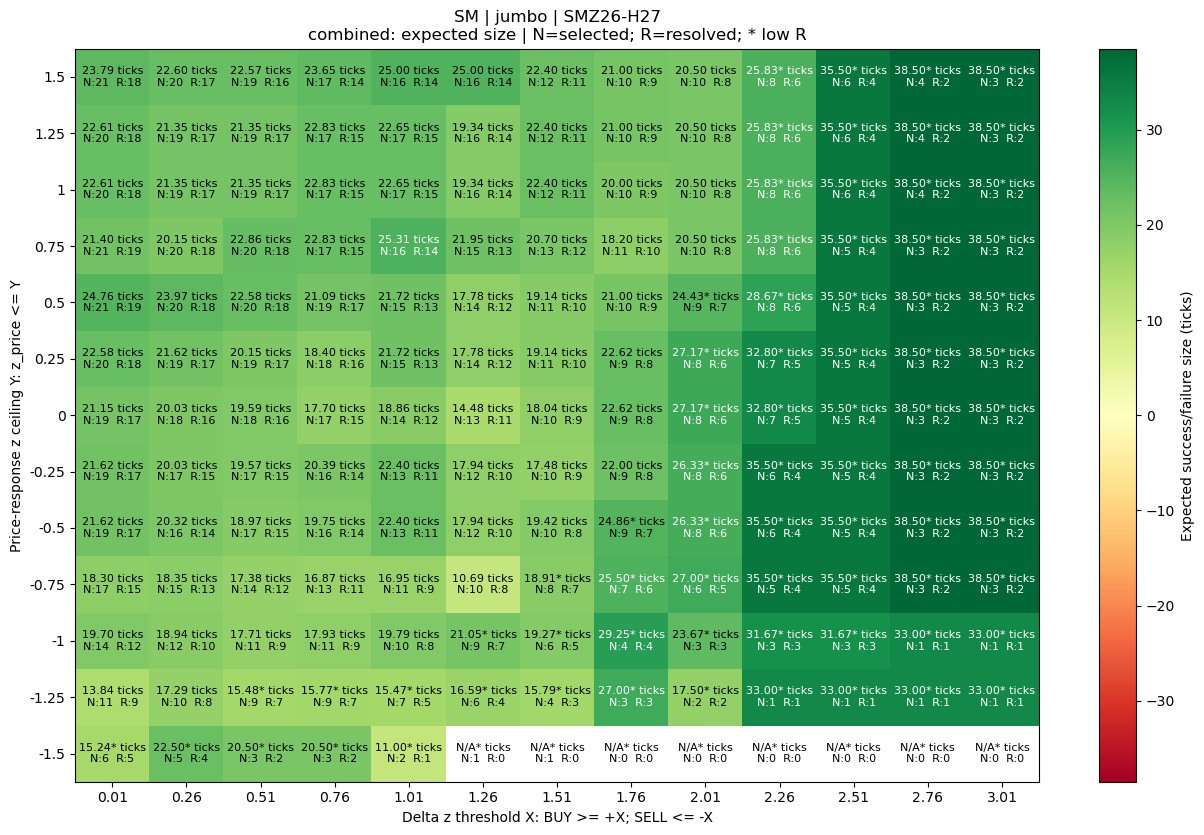

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,0.01,1.50,23.785714,21,18,17,1,26.117647,15.857143,0,3,215
1,combined,0.01,1.25,22.607143,20,18,15,3,30.800000,18.357143,0,2,206
2,combined,0.01,1.00,22.607143,20,18,15,3,30.800000,18.357143,0,2,197
3,combined,0.01,0.75,21.404135,21,19,16,3,28.812500,18.107143,0,2,180
4,combined,0.01,0.50,24.763158,21,19,17,2,30.058824,20.250000,0,2,157
...,...,...,...,...,...,...,...,...,...,...,...,...,...
164,combined,3.01,-0.50,38.500000,3,2,2,0,38.500000,NaN,0,1,0
165,combined,3.01,-0.75,38.500000,3,2,2,0,38.500000,NaN,0,1,0
166,combined,3.01,-1.00,33.000000,1,1,1,0,33.000000,NaN,0,0,0
167,combined,3.01,-1.25,33.000000,1,1,1,0,33.000000,NaN,0,0,0


SMZ26-K27


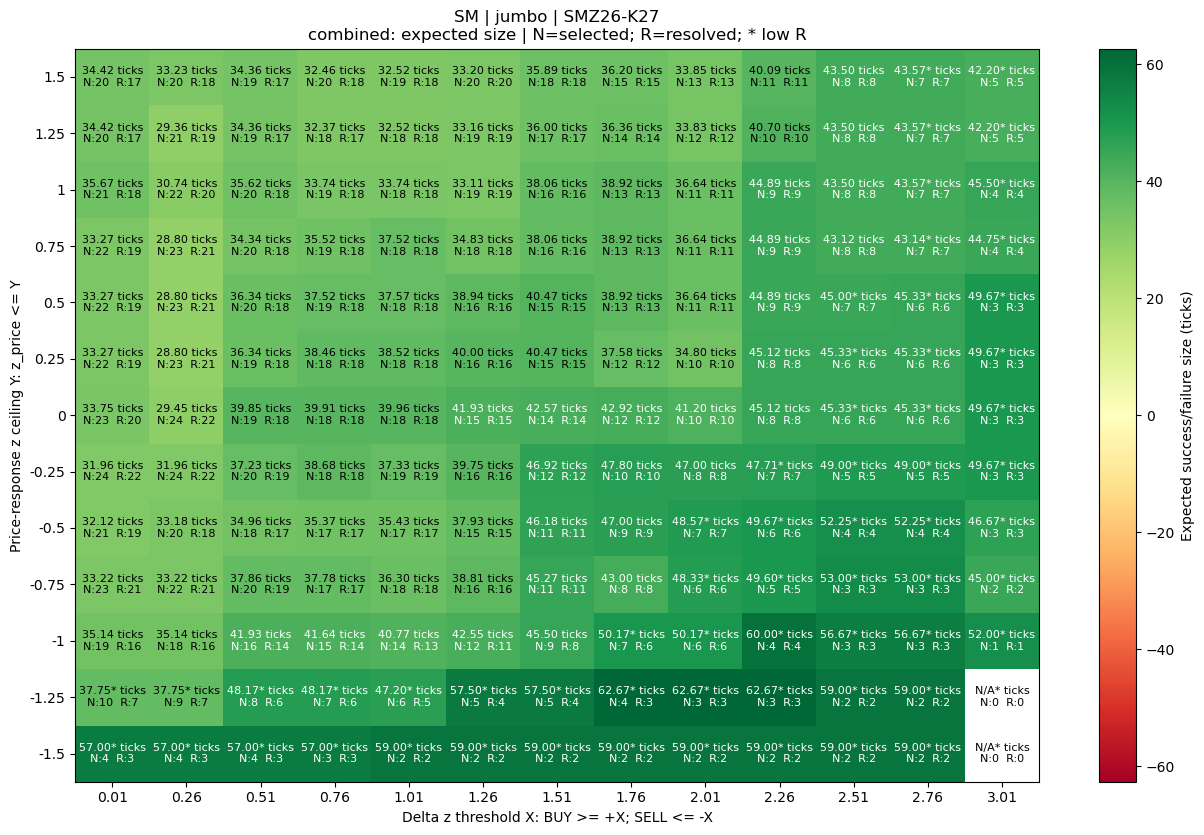

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,0.01,1.50,34.415966,20,17,15,2,41.933333,21.964286,0,3,229
1,combined,0.01,1.25,34.415966,20,17,15,2,41.933333,21.964286,0,3,224
2,combined,0.01,1.00,35.670635,21,18,16,2,42.875000,21.964286,0,3,210
3,combined,0.01,0.75,33.266917,22,19,17,2,39.764706,21.964286,0,3,193
4,combined,0.01,0.50,33.266917,22,19,17,2,39.764706,21.964286,0,3,174
...,...,...,...,...,...,...,...,...,...,...,...,...,...
164,combined,3.01,-0.50,46.666667,3,3,3,0,46.666667,NaN,0,0,2
165,combined,3.01,-0.75,45.000000,2,2,2,0,45.000000,NaN,0,0,0
166,combined,3.01,-1.00,52.000000,1,1,1,0,52.000000,NaN,0,0,0
167,combined,3.01,-1.25,NaN,0,0,0,0,NaN,NaN,0,0,0


SMF27-K27


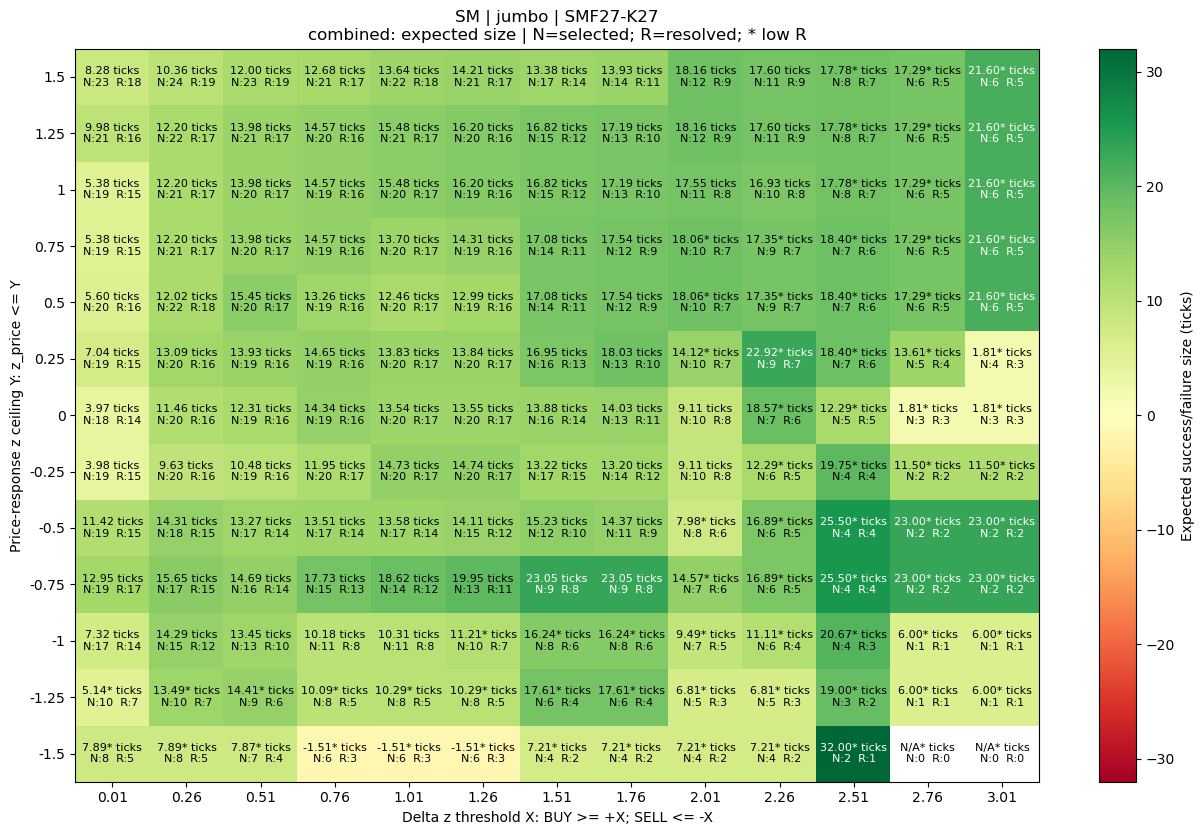

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,0.01,1.50,8.277778,23,18,12,6,21.416667,18.000000,1,4,175
1,combined,0.01,1.25,9.977679,21,16,11,5,22.636364,17.871429,1,4,171
2,combined,0.01,1.00,5.376190,19,15,9,6,21.888889,19.392857,1,3,162
3,combined,0.01,0.75,5.376190,19,15,9,6,21.888889,19.392857,1,3,150
4,combined,0.01,0.50,5.598214,20,16,9,7,24.666667,18.918367,1,3,133
...,...,...,...,...,...,...,...,...,...,...,...,...,...
164,combined,3.01,-0.50,23.000000,2,2,2,0,23.000000,NaN,0,0,11
165,combined,3.01,-0.75,23.000000,2,2,2,0,23.000000,NaN,0,0,9
166,combined,3.01,-1.00,6.000000,1,1,1,0,6.000000,NaN,0,0,4
167,combined,3.01,-1.25,6.000000,1,1,1,0,6.000000,NaN,0,0,0


SMF27-N27


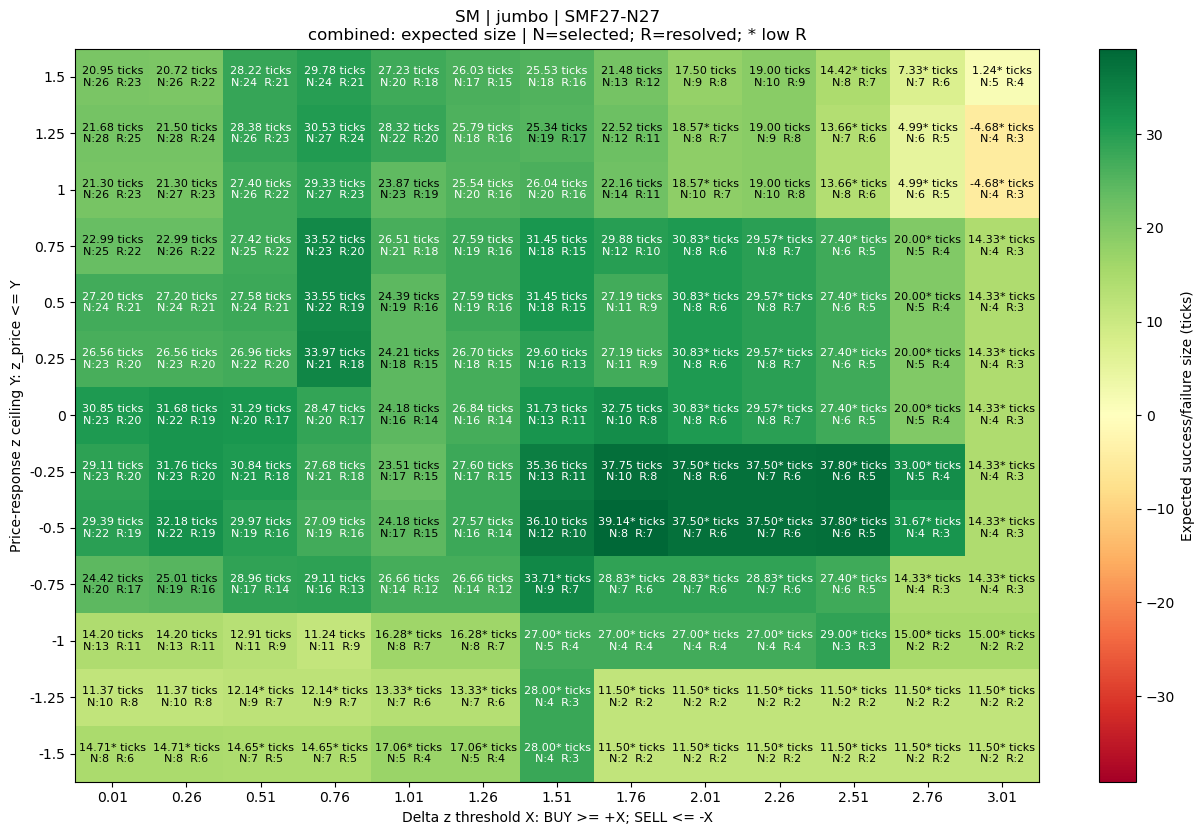

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,0.01,1.50,20.951863,26,23,19,4,29.473684,19.526786,0,3,197
1,combined,0.01,1.25,21.675714,28,25,20,5,31.900000,19.221429,0,3,187
2,combined,0.01,1.00,21.299689,26,23,18,5,32.555556,19.221429,0,3,173
3,combined,0.01,0.75,22.987013,25,22,17,5,35.470588,19.457143,0,3,162
4,combined,0.01,0.50,27.200680,24,21,17,4,38.352941,20.196429,0,3,147
...,...,...,...,...,...,...,...,...,...,...,...,...,...
164,combined,3.01,-0.50,14.333333,4,3,3,0,14.333333,NaN,0,1,2
165,combined,3.01,-0.75,14.333333,4,3,3,0,14.333333,NaN,0,1,2
166,combined,3.01,-1.00,15.000000,2,2,2,0,15.000000,NaN,0,0,1
167,combined,3.01,-1.25,11.500000,2,2,2,0,11.500000,NaN,0,0,0


SMH27-N27


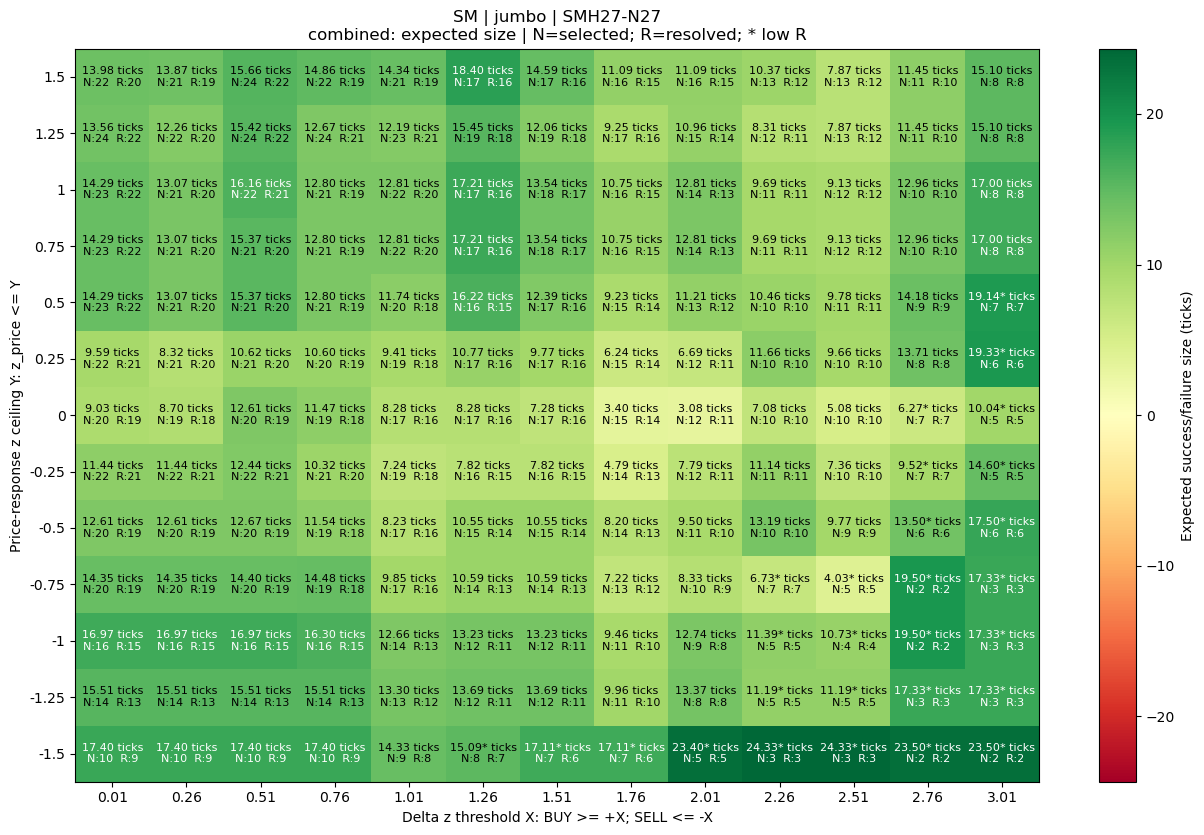

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,0.01,1.50,13.976786,22,20,17,3,18.882353,13.821429,0,2,206
1,combined,0.01,1.25,13.555195,24,22,18,4,19.555556,13.446429,0,2,190
2,combined,0.01,1.00,14.290584,23,22,19,3,18.684211,13.535714,0,1,176
3,combined,0.01,0.75,14.290584,23,22,19,3,18.684211,13.535714,0,1,170
4,combined,0.01,0.50,14.290584,23,22,19,3,18.684211,13.535714,0,1,158
...,...,...,...,...,...,...,...,...,...,...,...,...,...
164,combined,3.01,-0.50,17.500000,6,6,6,0,17.500000,NaN,0,0,4
165,combined,3.01,-0.75,17.333333,3,3,3,0,17.333333,NaN,0,0,0
166,combined,3.01,-1.00,17.333333,3,3,3,0,17.333333,NaN,0,0,0
167,combined,3.01,-1.25,17.333333,3,3,3,0,17.333333,NaN,0,0,0


In [1]:
# Copy this complete block into a notebook cell. The existing notebook is not edited.
import sys
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = Path(
    r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis"
)
if str(PROJECT_DIR.parent) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR.parent))

# Reload edited config/module even if this notebook kernel imported older versions.
config = importlib.import_module("market_analysis.config")
importlib.reload(config)
analysis = importlib.import_module("market_analysis.finding_threshold.expected_profit_analysis")
importlib.reload(analysis)

PRODUCT_CODE = "SM"                     # "SM" or "BO"
FRONT_N = 5                            # five spreads AND five jumbos
CANDLE_LENGTHS = [1, 2, 3, 5]           # any positive integer lengths
MODE = "combined"                      # "separate" + [1] for only 1D

# X displays POSITIVE magnitudes but selects BOTH signed z_delta tails.
# Y is a ceiling on z-score of ABSOLUTE price displacement, on BOTH sides.
# np.arange excludes its stop; change these ranges/steps as you like.
DELTA_Z_GRID = np.round(np.arange(0.01, 3.25, 0.25), 6)
PRICE_Z_GRID = np.round(np.arange(1.5, -1.75, -0.25), 6)

PARAMS = dict(config.ABSORPTION_EXPECTED_PROFIT)
PARAMS.update({
    "months_back": 5,                  # October run -> 1 June onward
    "baseline_window": 15,
    "baseline_min_periods": 15,        # must not exceed baseline_window
    "volume_window": 5,
    "atr_window": 5,
    "atr_period": 14,
    "stop_atr_mult": 1.5,              # configurable, fixed at signal time
    "required_move_ticks": 2,          # required profit BEFORE first stop
    "forward_days": 10,               # future RAW 1D trading bars
})

run = analysis.run_expected_profit_analysis(
    product_code=PRODUCT_CODE,
    candle_lengths=CANDLE_LENGTHS,
    mode=MODE,
    params=PARAMS,
    delta_z_grid=DELTA_Z_GRID,
    price_z_grid=PRICE_Z_GRID,
    front_n=FRONT_N,
    save_outputs=False,
)

print(f"Analysis: {run['analysis_start'].date()} to {run['analysis_end'].date()}")
if run["errors"]:
    display(pd.DataFrame(list(run["errors"].items()), columns=["Instrument", "Error"]))

# ONE heatmap per individual instrument in combined mode: five spreads plus
# five jumbos, when all instruments have data. BUY and SELL fold within each
# instrument only. No pooling across instruments or structure types.
for structure, instruments in run["universe"].items():
    print(f"\n{structure.upper()}")
    for instrument in instruments:
        result = run["instruments"].get(instrument)
        if result is None:
            continue  # The fetch/analysis error is already reported above.
        print(instrument)
        groups = list(dict.fromkeys(result["threshold_table"]["analysis_group"]))
        for group in groups:
            figure = analysis.plot_expected_profit_heatmap(result, analysis_group=group)
            plt.show()
            plt.close(figure)

        # Exact counts/payoff sizes behind this instrument's cells.
        display(result["threshold_table"][[
            "analysis_group", "delta_z_threshold", "price_z_threshold",
            "expected_profit_ticks", "n_signals", "n_resolved", "n_success", "n_failure",
            "avg_success_ticks", "avg_failure_ticks", "n_unresolved", "n_censored",
            "n_suppressed",
        ]])


BOZ26-F27: 87 raw bars; warmup sufficient=True
BOF27-H27: 87 raw bars; warmup sufficient=True
BOH27-K27: 87 raw bars; warmup sufficient=True
BOK27-N27: 87 raw bars; warmup sufficient=True
BON27-Q27: 87 raw bars; warmup sufficient=True
BOZ26-H27: 87 raw bars; warmup sufficient=True
BOZ26-K27: 87 raw bars; warmup sufficient=True
BOF27-K27: 87 raw bars; warmup sufficient=True
BOF27-N27: 87 raw bars; warmup sufficient=False
BOH27-N27: 87 raw bars; warmup sufficient=True
Analysis: 2026-06-01 to 2026-10-04

SPREAD
BOZ26-F27


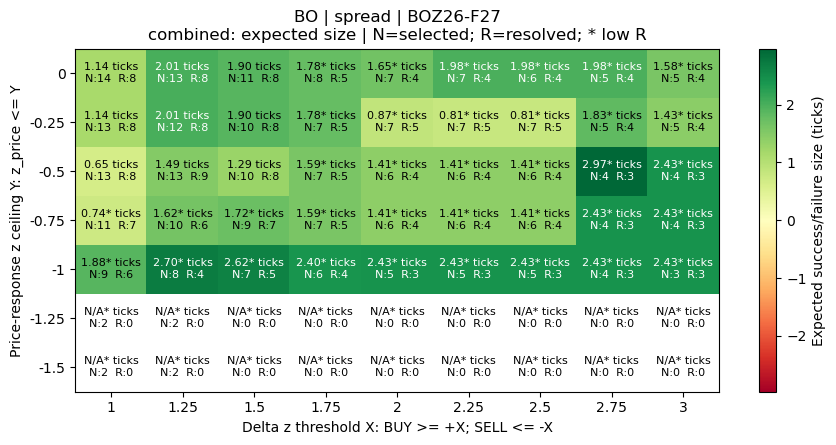

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,1.0,0.00,1.144643,14,8,5,3,2.860000,1.714286,3,3,47
1,combined,1.0,-0.25,1.144643,13,8,5,3,2.860000,1.714286,3,2,37
2,combined,1.0,-0.50,0.647321,13,8,4,4,3.025000,1.730357,3,2,25
3,combined,1.0,-0.75,0.737755,11,7,4,3,2.550000,1.678571,2,2,16
4,combined,1.0,-1.00,1.879762,9,6,5,1,2.620000,1.821429,1,2,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,combined,3.0,-0.50,2.433333,4,3,3,0,2.433333,NaN,1,0,0
59,combined,3.0,-0.75,2.433333,4,3,3,0,2.433333,NaN,1,0,0
60,combined,3.0,-1.00,2.433333,3,3,3,0,2.433333,NaN,0,0,0
61,combined,3.0,-1.25,NaN,0,0,0,0,NaN,NaN,0,0,0


BOF27-H27


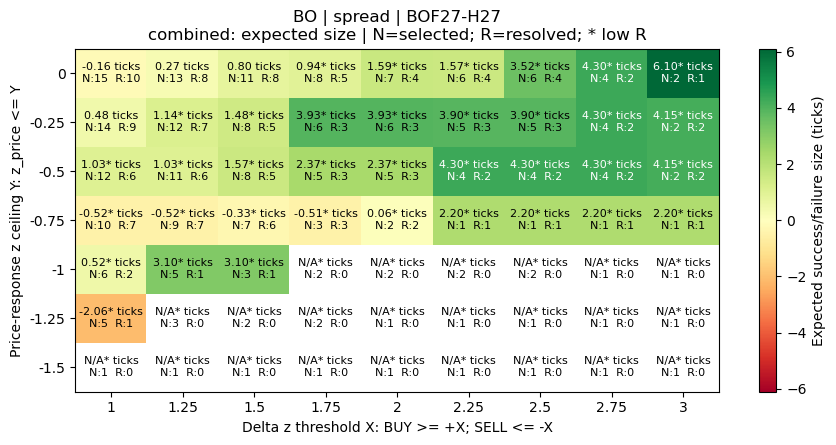

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,1.0,0.00,-0.162143,15,10,3,7,3.666667,1.803061,3,2,43
1,combined,1.0,-0.25,0.476190,14,9,4,5,3.375000,1.842857,3,2,35
2,combined,1.0,-0.50,1.026786,12,6,3,3,3.900000,1.846429,4,2,24
3,combined,1.0,-0.75,-0.523980,10,7,2,5,2.650000,1.793571,2,1,15
4,combined,1.0,-1.00,0.521429,6,2,1,1,3.100000,2.057143,3,1,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,combined,3.0,-0.50,4.150000,2,2,2,0,4.150000,NaN,0,0,4
59,combined,3.0,-0.75,2.200000,1,1,1,0,2.200000,NaN,0,0,3
60,combined,3.0,-1.00,NaN,1,0,0,0,NaN,NaN,1,0,1
61,combined,3.0,-1.25,NaN,1,0,0,0,NaN,NaN,1,0,1


BOH27-K27


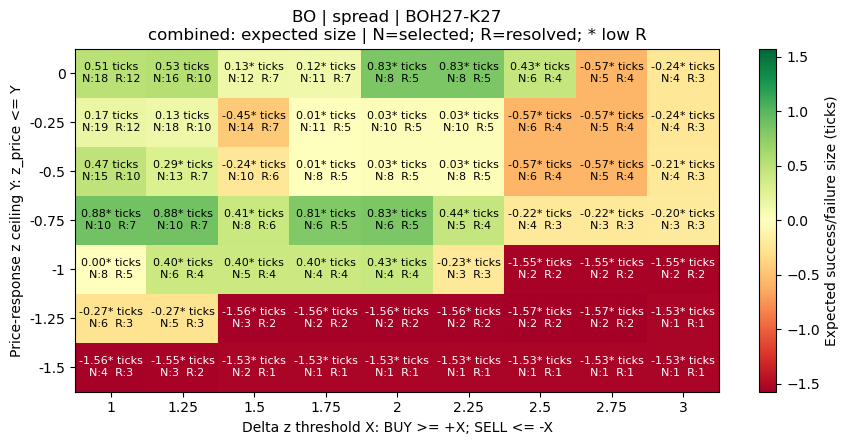

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,1.0,0.00,0.507738,18,12,6,6,2.583333,1.567857,4,2,70
1,combined,1.0,-0.25,0.170238,19,12,5,7,2.620000,1.579592,4,3,57
2,combined,1.0,-0.50,0.470714,15,10,5,5,2.540000,1.598571,3,2,41
3,combined,1.0,-0.75,0.880612,10,7,4,3,2.725000,1.578571,2,1,28
4,combined,1.0,-1.00,0.003571,8,5,2,3,2.350000,1.560714,2,1,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,combined,3.0,-0.50,-0.213095,4,3,1,2,2.500000,1.569643,0,1,8
59,combined,3.0,-0.75,-0.198810,3,3,1,2,2.500000,1.548214,0,0,2
60,combined,3.0,-1.00,-1.548214,2,2,0,2,NaN,1.548214,0,0,0
61,combined,3.0,-1.25,-1.532143,1,1,0,1,NaN,1.532143,0,0,0


BOK27-N27


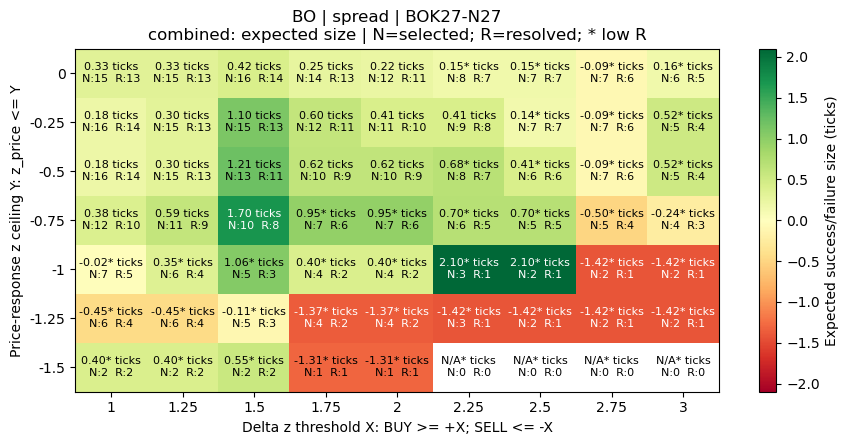

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,1.0,0.00,0.327747,15,13,6,7,2.383333,1.434184,1,1,59
1,combined,1.0,-0.25,0.182908,16,14,6,8,2.350000,1.442411,1,1,42
2,combined,1.0,-0.50,0.182143,16,14,6,8,2.350000,1.443750,1,1,33
3,combined,1.0,-0.75,0.378571,12,10,5,5,2.240000,1.482857,1,1,24
4,combined,1.0,-1.00,-0.017857,7,5,2,3,2.050000,1.396429,2,0,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,combined,3.0,-0.50,0.523214,5,4,2,2,2.450000,1.403571,0,1,8
59,combined,3.0,-0.75,-0.235714,4,3,1,2,2.100000,1.403571,0,1,4
60,combined,3.0,-1.00,-1.425000,2,1,0,1,NaN,1.425000,1,0,0
61,combined,3.0,-1.25,-1.425000,2,1,0,1,NaN,1.425000,1,0,0


BON27-Q27


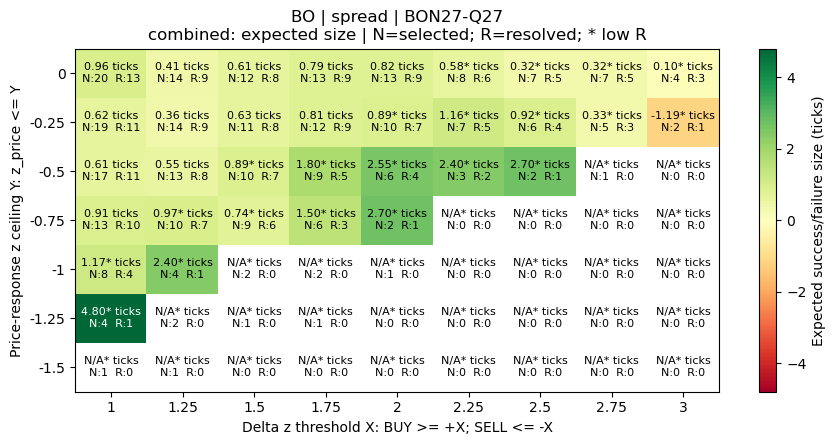

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,1.0,0.00,0.955769,20,13,7,6,2.857143,1.262500,4,3,45
1,combined,1.0,-0.25,0.624675,19,11,5,6,3.020000,1.371429,5,3,32
2,combined,1.0,-0.50,0.605195,17,11,5,6,3.020000,1.407143,3,3,19
3,combined,1.0,-0.75,0.905714,13,10,5,5,3.140000,1.328571,2,1,8
4,combined,1.0,-1.00,1.167857,8,4,2,2,3.600000,1.264286,2,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,combined,3.0,-0.50,NaN,0,0,0,0,NaN,NaN,0,0,0
59,combined,3.0,-0.75,NaN,0,0,0,0,NaN,NaN,0,0,0
60,combined,3.0,-1.00,NaN,0,0,0,0,NaN,NaN,0,0,0
61,combined,3.0,-1.25,NaN,0,0,0,0,NaN,NaN,0,0,0



JUMBO
BOZ26-H27


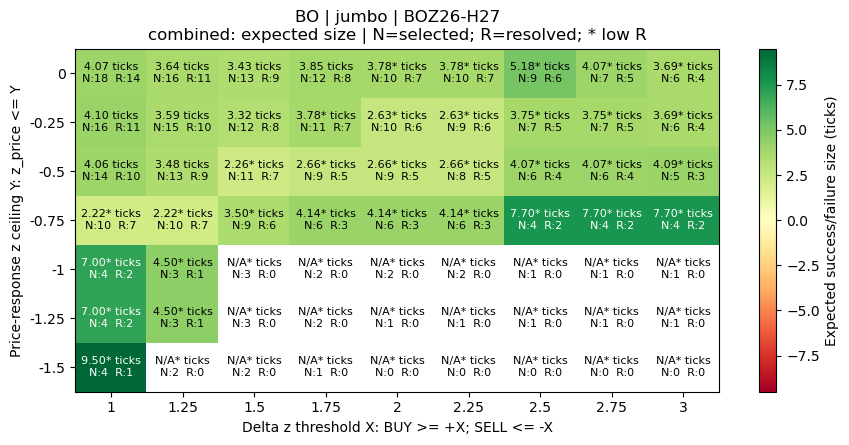

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,1.0,0.00,4.067857,18,14,11,3,6.090909,3.350000,2,2,50
1,combined,1.0,-0.25,4.104545,16,11,8,3,6.900000,3.350000,3,2,41
2,combined,1.0,-0.50,4.055000,14,10,7,3,7.228571,3.350000,2,2,29
3,combined,1.0,-0.75,2.221429,10,7,4,3,6.400000,3.350000,2,1,17
4,combined,1.0,-1.00,7.000000,4,2,2,0,7.000000,NaN,1,1,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,combined,3.0,-0.50,4.090476,5,3,2,1,7.700000,3.128571,1,1,3
59,combined,3.0,-0.75,7.700000,4,2,2,0,7.700000,NaN,1,1,1
60,combined,3.0,-1.00,NaN,1,0,0,0,NaN,NaN,0,1,0
61,combined,3.0,-1.25,NaN,1,0,0,0,NaN,NaN,0,1,0


BOZ26-K27


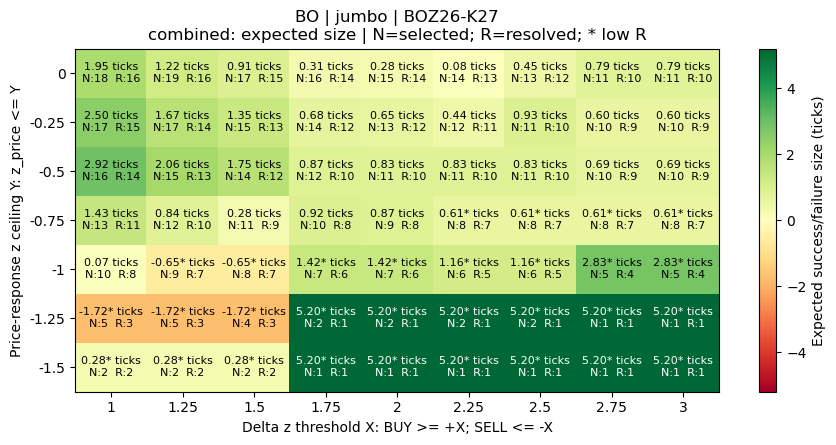

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,1.0,0.00,1.947768,18,16,10,6,5.990000,4.789286,0,2,69
1,combined,1.0,-0.25,2.503333,17,15,10,5,6.230000,4.950000,0,2,57
2,combined,1.0,-0.50,2.925000,16,14,10,4,6.120000,5.062500,0,2,43
3,combined,1.0,-0.75,1.431818,13,11,7,4,5.142857,5.062500,0,2,32
4,combined,1.0,-1.00,0.068750,10,8,4,4,5.200000,5.062500,1,1,16
...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,combined,3.0,-0.50,0.686905,10,9,5,4,5.100000,4.829464,0,1,16
59,combined,3.0,-0.75,0.605102,8,7,4,3,4.750000,4.921429,0,1,12
60,combined,3.0,-1.00,2.829464,5,4,3,1,5.233333,4.382143,0,1,6
61,combined,3.0,-1.25,5.200000,1,1,1,0,5.200000,NaN,0,0,2


BOF27-K27


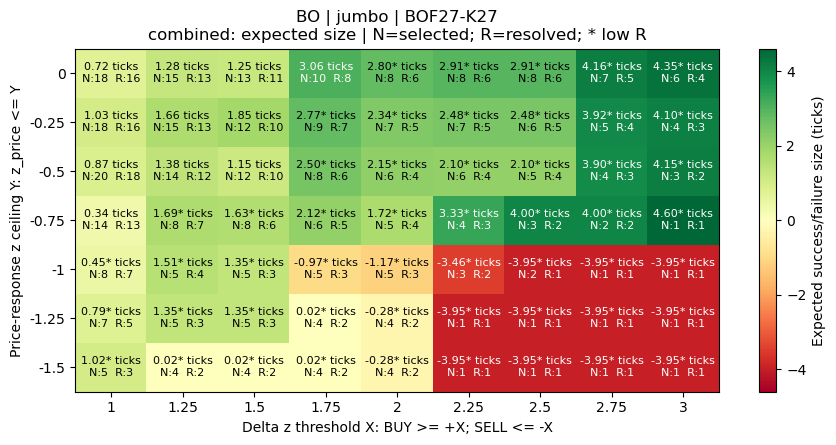

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,1.0,0.00,0.724330,18,16,9,7,3.688889,3.087245,1,1,65
1,combined,1.0,-0.25,1.026116,18,16,10,6,3.520000,3.130357,1,1,53
2,combined,1.0,-0.50,0.874206,20,18,11,7,3.454545,3.180612,1,1,36
3,combined,1.0,-0.75,0.338187,14,13,7,6,3.314286,3.133929,0,1,19
4,combined,1.0,-1.00,0.448980,8,7,4,3,3.250000,3.285714,0,1,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,combined,3.0,-0.50,4.150000,3,2,2,0,4.150000,NaN,0,1,1
59,combined,3.0,-0.75,4.600000,1,1,1,0,4.600000,NaN,0,0,1
60,combined,3.0,-1.00,-3.953571,1,1,0,1,NaN,3.953571,0,0,0
61,combined,3.0,-1.25,-3.953571,1,1,0,1,NaN,3.953571,0,0,0


BOF27-N27


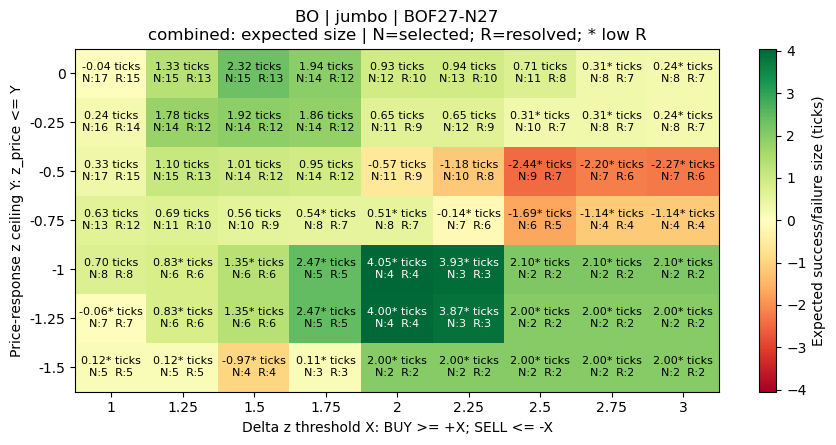

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,1.0,0.00,-0.041905,17,15,7,8,5.071429,4.516071,0,2,63
1,combined,1.0,-0.25,0.243622,16,14,7,7,5.071429,4.584184,0,2,56
2,combined,1.0,-0.50,0.325476,17,15,8,7,4.450000,4.388265,0,2,34
3,combined,1.0,-0.75,0.626488,13,12,7,5,4.228571,4.416429,0,1,17
4,combined,1.0,-1.00,0.698661,8,8,5,3,3.820000,4.503571,0,0,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,combined,3.0,-0.50,-2.274405,7,6,2,4,2.000000,4.411607,0,1,5
59,combined,3.0,-0.75,-1.142857,4,4,2,2,2.000000,4.285714,0,0,4
60,combined,3.0,-1.00,2.100000,2,2,2,0,2.100000,NaN,0,0,1
61,combined,3.0,-1.25,2.000000,2,2,2,0,2.000000,NaN,0,0,0


BOH27-N27


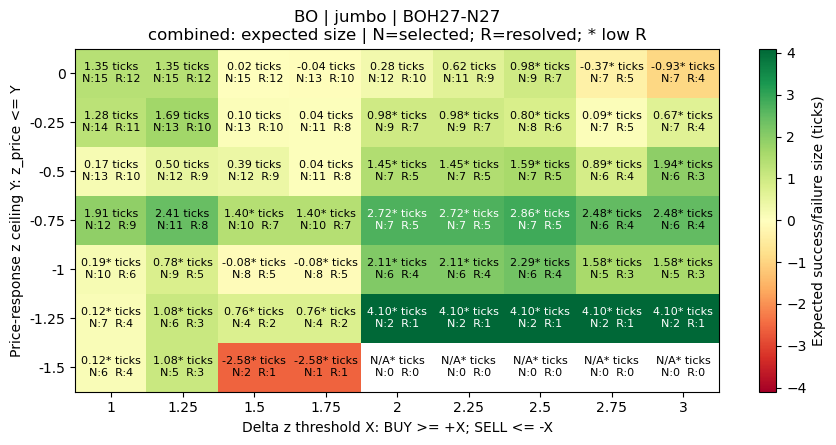

,analysis_group,delta_z_threshold,price_z_threshold,expected_profit_ticks,n_signals,n_resolved,n_success,n_failure,avg_success_ticks,avg_failure_ticks,n_unresolved,n_censored,n_suppressed
0,combined,1.0,0.00,1.348810,15,12,7,5,4.357143,2.862857,1,2,71
1,combined,1.0,-0.25,1.283442,14,11,6,5,4.733333,2.856429,1,2,54
2,combined,1.0,-0.50,0.171429,13,10,4,6,4.650000,2.814286,1,2,42
3,combined,1.0,-0.75,1.911111,12,9,6,3,4.216667,2.700000,1,2,28
4,combined,1.0,-1.00,0.188690,10,6,3,3,3.066667,2.689286,1,3,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,combined,3.0,-0.50,1.936905,6,3,2,1,4.250000,2.689286,0,3,8
59,combined,3.0,-0.75,2.477679,6,4,3,1,4.200000,2.689286,0,2,3
60,combined,3.0,-1.00,1.580952,5,3,2,1,3.700000,2.657143,0,2,1
61,combined,3.0,-1.25,4.100000,2,1,1,0,4.100000,NaN,0,1,0


In [3]:
# Copy this complete block into a notebook cell. The existing notebook is not edited.
import sys
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = Path(
    r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis"
)
if str(PROJECT_DIR.parent) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR.parent))

# Reload edited config/module even if this notebook kernel imported older versions.
config = importlib.import_module("market_analysis.config")
importlib.reload(config)
analysis = importlib.import_module("market_analysis.finding_threshold.expected_profit_analysis")
importlib.reload(analysis)

PRODUCT_CODE = "BO"                     # "SM" or "BO"
FRONT_N = 5                            # five spreads AND five jumbos
CANDLE_LENGTHS = [1, 2, 3, 5]           # any positive integer lengths
MODE = "combined"                      # "separate" + [1] for only 1D

# X displays POSITIVE magnitudes but selects BOTH signed z_delta tails.
# Y is a ceiling on z-score of ABSOLUTE price displacement, on BOTH sides.
# np.arange excludes its stop; change these ranges/steps as you like.
DELTA_Z_GRID = np.round(np.arange(1.0, 3.25, 0.25), 6)
PRICE_Z_GRID = np.round(np.arange(0.0, -1.75, -0.25), 6)

PARAMS = dict(config.ABSORPTION_EXPECTED_PROFIT)
PARAMS.update({
    "months_back": 5,                  # October run -> 1 June onward
    "baseline_window": 15,
    "baseline_min_periods": 15,        # must not exceed baseline_window
    "volume_window": 5,
    "atr_window": 5,
    "atr_period": 14,
    "stop_atr_mult": 1.5,              # configurable, fixed at signal time
    "required_move_ticks": 2,          # required profit BEFORE first stop
    "forward_days": 10,               # future RAW 1D trading bars
})

run = analysis.run_expected_profit_analysis(
    product_code=PRODUCT_CODE,
    candle_lengths=CANDLE_LENGTHS,
    mode=MODE,
    params=PARAMS,
    delta_z_grid=DELTA_Z_GRID,
    price_z_grid=PRICE_Z_GRID,
    front_n=FRONT_N,
    save_outputs=False,
)

print(f"Analysis: {run['analysis_start'].date()} to {run['analysis_end'].date()}")
if run["errors"]:
    display(pd.DataFrame(list(run["errors"].items()), columns=["Instrument", "Error"]))

# ONE heatmap per individual instrument in combined mode: five spreads plus
# five jumbos, when all instruments have data. BUY and SELL fold within each
# instrument only. No pooling across instruments or structure types.
for structure, instruments in run["universe"].items():
    print(f"\n{structure.upper()}")
    for instrument in instruments:
        result = run["instruments"].get(instrument)
        if result is None:
            continue  # The fetch/analysis error is already reported above.
        print(instrument)
        groups = list(dict.fromkeys(result["threshold_table"]["analysis_group"]))
        for group in groups:
            figure = analysis.plot_expected_profit_heatmap(result, analysis_group=group)
            plt.show()
            plt.close(figure)

        # Exact counts/payoff sizes behind this instrument's cells.
        display(result["threshold_table"][[
            "analysis_group", "delta_z_threshold", "price_z_threshold",
            "expected_profit_ticks", "n_signals", "n_resolved", "n_success", "n_failure",
            "avg_success_ticks", "avg_failure_ticks", "n_unresolved", "n_censored",
            "n_suppressed",
        ]])
